## Project goal: explore how weather and other factors relate to bike rentals.

#### Column guide for `hour.csv` and `day.csv` (`hr` is only included in `hour.csv`)

	- instant: record index
	- dteday : date
	- season : season (1:spring, 2:summer, 3:fall, 4:winter)
	- yr : year (0: 2011, 1:2012)
	- mnth : month ( 1 to 12)
	- hr : hour (0 to 23)
	- holiday : weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)
	- weekday : day of the week (0: Sunday, 1: Monday, ..., 6: Saturday)
	- workingday : if day is neither weekend nor holiday is 1, otherwise is 0.
	+ weathersit :
		- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
		- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
		- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
		- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
	- temp : Normalized temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-8, t_max=+39 (only in hourly scale)
	- atemp: Normalized feeling temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-16, t_max=+50 (only in hourly scale)
	- hum: Normalized humidity. The values are divided to 100 (max)
	- windspeed: Normalized wind speed. The values are divided to 67 (max)
	- casual: count of casual users
	- registered: count of registered users
	- cnt: count of total rental bikes including both casual and registered



In [14]:
# Import pandas to load and work with the dataset.
import pandas as pd

# Read the hourly rental data from the project dataset folder.
hour_df = pd.read_csv("bike+sharing+dataset/hour.csv")
# Display the DataFrame so we can inspect the loaded data.
hour_df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


## The documentation reports no missing values, but I will check the dataset.

In [13]:
# Show each column's data type and non-missing value count.
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


## Check whether the dataset contains duplicate rows

In [18]:
# Return True if at least one complete row is duplicated.
hour_df.duplicated().any()

np.False_

In [37]:
# Convert date strings to datetime values so they can be sorted as dates.
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
# Put observations in chronological order before making a time-based split.
hour_df = hour_df.sort_values("dteday")

In [40]:
# Set the value to predict: total rentals per hour.
y = hour_df["cnt"]
# Keep useful predictors, excluding the target, its component counts, row ID, and raw date.
X = hour_df.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])
# Display the predictor columns for a quick check.

X

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000
23,1,0,1,23,0,6,0,2,0.46,0.4545,0.88,0.2985
22,1,0,1,22,0,6,0,2,0.40,0.4091,0.94,0.2239
21,1,0,1,21,0,6,0,2,0.40,0.4091,0.87,0.1940
20,1,0,1,20,0,6,0,2,0.40,0.4091,0.87,0.2537
...,...,...,...,...,...,...,...,...,...,...,...,...
17356,1,1,12,1,0,1,1,1,0.18,0.1818,0.55,0.1940
17355,1,1,12,0,0,1,1,1,0.18,0.1818,0.55,0.1940
17377,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343
17365,1,1,12,10,0,1,1,2,0.20,0.2121,0.69,0.1343


## Training a linear regression model

In [41]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert dates to datetime and sort by date and hour to preserve time order.
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
hour_df = hour_df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# Separate the target (total rentals) from the predictor features.
y = hour_df["cnt"]
# Exclude cnt (the answer), casual/registered (components of cnt), instant (row ID),
# and dteday (raw date); calendar features such as month, weekday, and hour remain.
X = hour_df.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])

# Use the first 80% of chronologically ordered rows for training and the rest for testing.
split_index = int(len(hour_df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Fit a simple linear regression model using the training portion.
model = LinearRegression()
model.fit(X_train, y_train)

# Predict rentals for the later, held-out test period.
predictions = model.predict(X_test)

# Report average absolute error and root mean squared error, in rental-count units.
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

MAE: 138.29175310827338
RMSE: 183.2778473101198


## Comaring with a Random Forest model

In [46]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

models = {"Baseline": DummyRegressor(strategy = "mean"), "Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators = 200, random_state = 42, n_jobs = -1)}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results[name] = {"MAE": mean_absolute_error(y_test, predictions),
                     "RMSE": np.sqrt(mean_squared_error(y_test, predictions))}

pd.DataFrame(results).T


,MAE,RSME
Baseline,174.984601,232.608375
Linear Regression,138.291753,183.277847
Random Forest,45.134666,69.874077


## Comparison

### The Random Forest performed substantially better than Linear Regression on the test data. Its MAE was 45 rentals, compared with 138 for Linear Regression, while its RMSE was 69 compared with 183. This means the Random Forest’s predictions were considerably closer to the actual hourly rental counts.

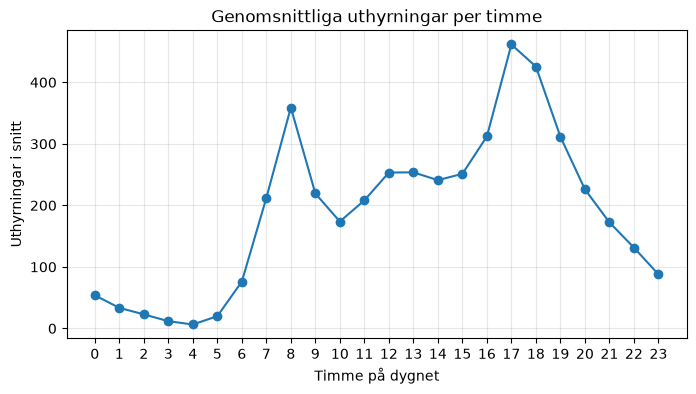

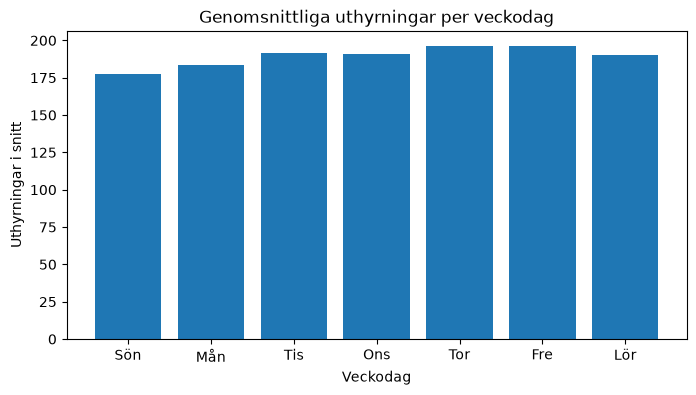

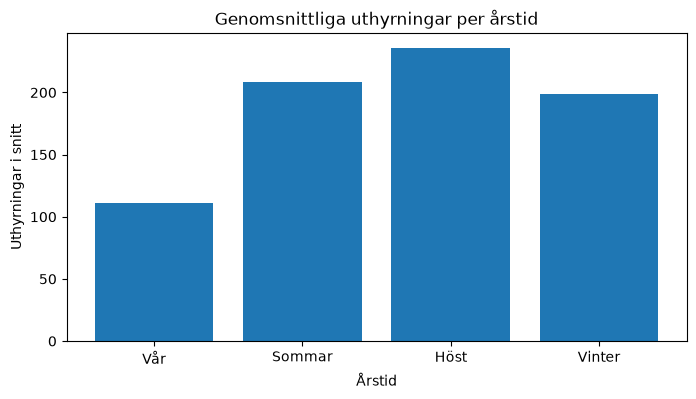

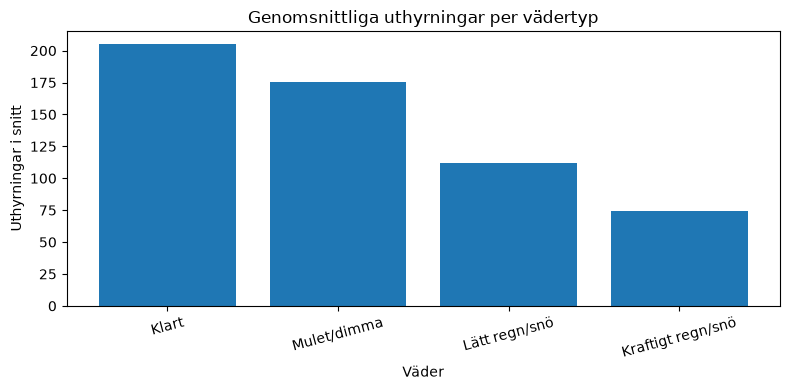

In [45]:
# Import pyplot for creating the charts.
import matplotlib.pyplot as plt

# Labels match the dataset codes: weekdays 0-6, seasons 1-4, and weather 1-4.
weekday_labels = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
season_labels = ["Spring", "Summer", "Fall", "Winter"]
weather_labels = ["Clear", "Cloudy/mist", "Light rain/snow", "Heavy rain/snow"]

# Average rentals for each hour, then plot the daily usage pattern.
hourly_avg = hour_df.groupby("hr")["cnt"].mean()
plt.figure(figsize=(8, 4))
plt.plot(hourly_avg.index, hourly_avg.values, marker="o")
plt.title("Average rentals by hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()
plt.close()

# Average rentals by weekday; reindex keeps the displayed order Sunday through Saturday.
weekday_avg = hour_df.groupby("weekday")["cnt"].mean().reindex(range(7))
plt.figure(figsize=(8, 4))
plt.bar(weekday_labels, weekday_avg.values)
plt.title("Average rentals by weekday")
plt.xlabel("Weekday")
plt.ylabel("Average rentals")
plt.show()
plt.close()

# Average rentals by season; the labels follow season codes 1 through 4.
season_avg = hour_df.groupby("season")["cnt"].mean().reindex(range(1, 5))
plt.figure(figsize=(8, 4))
plt.bar(season_labels, season_avg.values)
plt.title("Average rentals by season")
plt.xlabel("Season")
plt.ylabel("Average rentals")
plt.show()
plt.close()

# Average rentals by weather category; higher weather codes indicate worse conditions.
weather_avg = hour_df.groupby("weathersit")["cnt"].mean().reindex(range(1, 5))
plt.figure(figsize=(8, 4))
plt.bar(weather_labels, weather_avg.values)
plt.title("Average rentals by weather")
plt.xlabel("Weather")
plt.ylabel("Average rentals")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
plt.close()




## Initial observations

Average rentals peak at 8 a.m. and 5 p.m. Counts are fairly similar across weekdays, with the fewest rentals on Sundays. Summer and fall have the highest average rental counts, while spring has the lowest, followed by winter. Rentals are lowest during heavy rain or snow (about 75 per hour) and light rain or snow (about 100 per hour). They are highest in clear weather (about 200 per hour), followed by misty or cloudy weather (about 175 per hour). These are descriptive patterns and do not by themselves show that weather or season causes the differences.

## Implications for bike availability

The hourly pattern is useful for short-term planning: more bikes should be available before the morning and evening peaks, especially around 8 a.m. and 5 p.m. Weekday differences are relatively small, so day of week may be less useful on its own than the hour. Season, temperature, and weather can help with broader planning: demand is generally higher in summer and fall and on clear, warmer days, and lower in rain or snow and at higher humidity. These patterns can guide how many bikes to prepare, but they describe associations rather than causes. The Random Forest's lower test errors suggest it is the most useful of the three tested models for predicting hourly demand in this dataset.

In [47]:
correlations = (hour_df.drop(columns =["casual", "registered", "instant"])
                .select_dtypes(include = "number")
                .corr()["cnt"]
                .sort_values(key=abs, ascending=False)
)

display(correlations)

cnt           1.000000
temp          0.404772
atemp         0.400929
hr            0.394071
hum          -0.322911
yr            0.250495
season        0.178056
weathersit   -0.142426
mnth          0.120638
windspeed     0.093234
holiday      -0.030927
workingday    0.030284
weekday       0.026900
Name: cnt, dtype: float64

`cnt = 1.0` is the correlation between `cnt` and itself, so it can be ignored.

The other values show moderate **positive relationships** between rentals and temperature (`temp` = 0.40, `atemp` = 0.40), as well as hour (`hr` = 0.39). Humidity has a moderate negative relationship (`hum` = -0.32). In this dataset, rentals tend to be higher at higher temperatures and lower at higher humidity levels. The relationship with `yr` (0.25) also suggests there were more rentals in 2012 than in 2011.

The remaining relationships are weaker. However, correlation only captures **linear** relationships, and some columns are category codes. For example, `weekday = 6` means Saturday; it does not mean Saturday is "six times" Sunday. A low correlation for `weekday`, `season`, or `weathersit` may therefore miss differences between categories. The charts and group averages are better for comparing them. Correlation shows association, not causation.